    User ID  Gender  Age  EstimatedSalary  Purchased
0  15624510    Male   19            19000          0
1  15810944    Male   35            20000          0
2  15668575  Female   26            43000          0
3  15603246  Female   27            57000          0
4  15804002    Male   19            76000          0


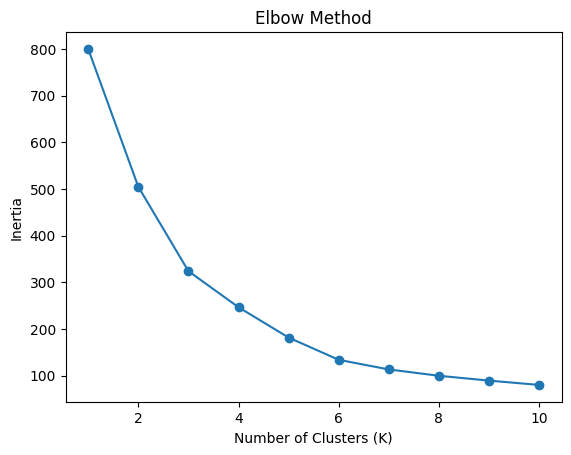

Cluster Centroids:
 [[4.60215827e+01 5.57841727e+04]
 [4.25802469e+01 1.22716049e+05]
 [2.89777778e+01 5.66833333e+04]]


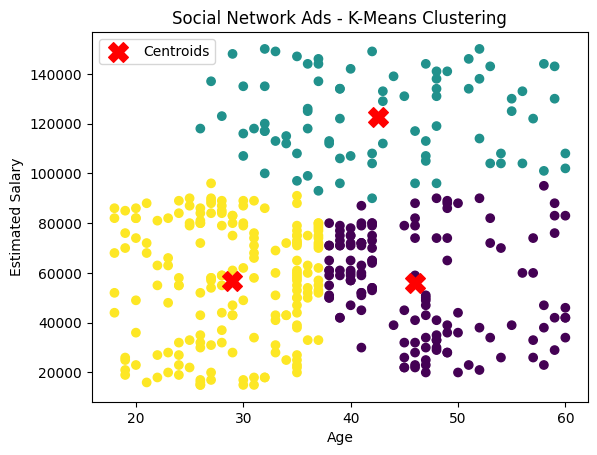

   Age  EstimatedSalary  Cluster
0   19            19000        2
1   35            20000        2
2   26            43000        2
3   27            57000        2
4   19            76000        2
5   27            58000        2
6   27            84000        2
7   32           150000        1
8   25            33000        2
9   35            65000        2


In [1]:

# 1. Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 2. Load dataset
df = pd.read_csv('/content/Social_Network_Ads.csv')
print(df.head())

# 3. Select features
X = df[['Age', 'EstimatedSalary']]

# 4. Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Elbow Method
inertia = []

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()

# 6. Apply K-Means (choose K = 3 for demonstration)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(X_scaled)

# 7. Get centroids
centroids = scaler.inverse_transform(kmeans.cluster_centers_)
print("Cluster Centroids:\n", centroids)

# 8. Visualize clusters
plt.scatter(df['Age'], df['EstimatedSalary'],
            c=df['Cluster'], cmap='viridis')

plt.scatter(centroids[:, 0], centroids[:, 1],
            color='red', marker='X', s=200, label='Centroids')

plt.xlabel('Age')
plt.ylabel('Estimated Salary')
plt.title('Social Network Ads - K-Means Clustering')
plt.legend()
plt.show()

# 9. Display results
print(df[['Age', 'EstimatedSalary', 'Cluster']].head(10))
